# Kingston University Coursework Brief 2026 2027

### Module Title: Applied Data Programming
### Assessment Title: Research Report and Visualisation

In [ ]:
# pip install pandas numpy matplotlib jupyter

In [1]:
# Import required Library
import pandas as pd
import numpy as np

In [2]:
# 1. Load dataset
df = pd.read_csv("dataset_coursework1-1.csv", low_memory=False)
print("Original headers:", df.columns.tolist())

Original headers: ['Incident ID', 'Offence Code', 'CR Number', 'Dispatch Date / Time', 'Start_Date_Time', 'End_Date_Time', 'NIBRS Code', 'Victims', 'Crime Name1', 'Crime Name2', 'Crime Name3', 'Police District Name', 'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place', 'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix', 'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude', 'Police District Number', 'Location']


In [3]:
# If the first row was actually data (no header), reload with header=None
if str(df.columns[0]).strip().isdigit():
    df = pd.read_csv("dataset_coursework1-1.csv", header=None, low_memory=False)
print(df.columns[0])

Incident ID


In [4]:
# Assign standard 30-column NIBRS names by position
# The data set Titles are not follow up standerd to written names
canonical_cols = [
    "Incident ID", "Offense Code", "CR Number", "Dispatch Date/Time",
    "Start Date/Time", "End Date/Time", "NIBRS Code", "Victims",
    "Crime Name 1", "Crime Name 2", "Crime Name 3", "Police District Name",
    "Block Address", "City", "State", "Zip Code", "Agency", "Place",
    "Sector", "Beat", "PRA", "Address Number", "Street Prefix",
    "Street Name", "Street Suffix", "Street Type", "Latitude",
    "Longitude", "Police District Number", "Geolocation"
]

#### Replace Columns Name Standerd Patterns

In [12]:
if df.shape[1] == 30:
    df.columns = canonical_cols
else:
    raise ValueError(f"Expected 30 columns, found {df.shape[1]}. Check separator/encoding.")

#### How many rows and Columns in the Data set

In [6]:
total_raw_rows = len(df)
print(f"Total raw rows: {total_raw_rows:,} | Columns: {df.shape[1]}")

Total raw rows: 508,106 | Columns: 30


In [7]:
# 2. Initial Data Quality Audit (Quantifying Missingness & Noise)
audit = pd.DataFrame({
    "dtype": df.dtypes,
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().sum() / total_raw_rows * 100).round(2),
    "unique_values": df.nunique()
})
print("\n--- Missingness & Cardinality Audit ---")
print(audit)


--- Missingness & Cardinality Audit ---
                          dtype  missing_count  missing_pct  unique_values
Incident ID               int64              0         0.00         467601
Offense Code             object              0         0.00            360
CR Number                 int64              0         0.00         467534
Dispatch Date/Time       object          73405        14.45         397963
Start Date/Time          object              0         0.00         372500
End Date/Time            object         282444        55.59         157941
NIBRS Code               object              0         0.00             54
Victims                   int64              0         0.00             10
Crime Name 1             object              0         0.00              4
Crime Name 2             object              0         0.00             54
Crime Name 3             object              0         0.00            360
Police District Name     object           1542         0.30

In [8]:
# Ensure numeric types for Latitude/Longitude/Victims
for num_col in ["Latitude", "Longitude", "Victims"]:
    df[num_col] = pd.to_numeric(df[num_col], errors="coerce")

zero_coords = ((df["Latitude"] == 0.0) | (df["Longitude"] == 0.0)).sum()
null_coords = (df["Latitude"].isna() | df["Longitude"].isna()).sum()
print(f"\nZeroed Coordinates (0.0): {zero_coords:,} ({zero_coords/total_raw_rows*100:.2f}%)")
print(f"Null Coordinates (NaN):   {null_coords:,} ({null_coords/total_raw_rows*100:.2f}%)")


Zeroed Coordinates (0.0): 24,648 (4.85%)
Null Coordinates (NaN):   0 (0.00%)


In [9]:
# 3. Date Parsing & Temporal Consistency Check
date_cols = ["Dispatch Date/Time", "Start Date/Time", "End Date/Time"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")

invalid_end = (df["End Date/Time"] < df["Start Date/Time"]).sum()
out_of_scope = ((df["Start Date/Time"] < "2016-07-01") | (df["Start Date/Time"] > "2026-09-10 23:59:59")).sum()
print(f"End Date < Start Date anomalies: {invalid_end:,} ({invalid_end/total_raw_rows*100:.2f}%)")
print(f"Out-of-scope timestamps:        {out_of_scope:,} ({out_of_scope/total_raw_rows*100:.2f}%)")

End Date < Start Date anomalies: 8,418 (1.66%)
Out-of-scope timestamps:        228 (0.04%)


In [61]:
# 4. Cleaning & Transformation
df_clean = df.copy()
df_clean.loc[(df_clean["Latitude"] == 0.0) | (df_clean["Longitude"] == 0.0), ["Latitude", "Longitude"]] = np.nan

df_clean["Dispatch_Status"] = np.where(df_clean["Dispatch Date/Time"].isna(), "Non-Dispatched", "Dispatched")
df_clean["Crime Name 1"] = df_clean["Crime Name 1"].fillna("Unknown / Unclassified")
df_clean["Police District Name"] = df_clean["Police District Name"].astype(str).str.strip().str.upper().replace("NAN", "UNKNOWN")
df_clean["City"] = df_clean["City"].astype(str).str.strip().str.upper().replace("NAN", "UNKNOWN")

df_clean.loc[df_clean["End Date/Time"] < df_clean["Start Date/Time"], "End Date/Time"] = pd.NaT

exact_dups = df_clean.duplicated(subset=["Incident ID"], keep=False).sum()
print(f"Exact duplicate Incident IDs dropped: {exact_dups:,}")


Exact duplicate Incident IDs dropped: 74,254


In [58]:
# Filter for all rows with a duplicated Incident ID
all_dups = df_clean[df_clean.duplicated(subset=["Incident ID"], keep=False)]

# Sort by Incident ID to group matching records together
all_dups = all_dups.sort_values(by="Incident ID")

print(f"Total rows involved in duplicates: {len(all_dups):,}")
display(all_dups) # Use print(all_dups) if not in a Jupyter notebook


Total rows involved in duplicates: 74,254


,Incident ID,Offense Code,CR Number,Dispatch Date/Time,Start Date/Time,End Date/Time,NIBRS Code,Victims,Crime Name 1,Crime Name 2,...,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Geolocation,Dispatch_Status
508079,201087097,5202,16033232,NaT,2016-07-01 00:04:00,NaT,520,1,Crime Against Society,Weapon Law Violations,...,13700.0,NaN,CONNECTICUT,NaN,AVE,39.07895,-77.0808,4D,"(39.0789, -77.0808)",Non-Dispatched
508078,201087097,5707,16033232,NaT,2016-07-01 00:04:00,NaT,90J,1,Crime Against Society,Trespass of Real Property,...,13700.0,NaN,CONNECTICUT,NaN,AVE,39.07895,-77.0808,4D,"(39.0789, -77.0808)",Non-Dispatched
508077,201087097,2303,16033232,NaT,2016-07-01 00:04:00,NaT,23C,1,Crime Against Property,Shoplifting,...,13700.0,NaN,CONNECTICUT,NaN,AVE,39.07895,-77.0808,4D,"(39.0789, -77.0808)",Non-Dispatched
508037,201087133,2602,16033268,NaT,2016-07-01 08:52:00,NaT,26A,1,Crime Against Property,False Pretenses/Swindle/Confidence Game,...,11800.0,NaN,ROCKVILLE,NaN,PIK,39.05040,-77.1148,2D,"(39.0504, -77.1148)",Non-Dispatched
508036,201087133,9199,16033268,NaT,2016-07-01 08:52:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,11800.0,NaN,ROCKVILLE,NaN,PIK,39.05040,-77.1148,2D,"(39.0504, -77.1148)",Non-Dispatched
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81,201590537,1399,260040049,2026-09-12 22:07:57,2026-09-12 22:07:00,NaT,13B,1,Crime Against Person,Simple Assault,...,1.0,E,DEER PARK,NaN,DR,39.13218,-77.1889,6D,"(39.1322, -77.1889)",Dispatched
77,201590543,5299,260040058,2026-09-13 00:06:31,2026-09-13 00:06:00,NaT,520,1,Crime Against Society,Weapon Law Violations,...,7400.0,NaN,NEW HAMPSHIRE,NaN,AVE,38.98337,-76.9883,TPPD,"(38.9834, -76.9883)",Dispatched
76,201590543,5212,260040058,2026-09-13 00:06:31,2026-09-13 00:06:00,NaT,520,1,Crime Against Society,Weapon Law Violations,...,7400.0,NaN,NEW HAMPSHIRE,NaN,AVE,38.98337,-76.9883,TPPD,"(38.9834, -76.9883)",Dispatched
110,201590553,1399,260040016,2026-09-12 16:42:48,2026-09-12 16:42:00,NaT,13B,1,Crime Against Person,Simple Assault,...,2000.0,NaN,DUNDEE,NaN,RD,39.08809,-77.1830,1D,"(39.0881, -77.183)",Dispatched


In [69]:
df_clean = df_clean.drop_duplicates(subset=["Incident ID"])
# Filter for all rows with a duplicated Incident ID
all_dups = df_clean[df_clean.duplicated(subset=["Incident ID"], keep=False)]
print(f"Total rows involved in duplicates: {len(all_dups):,}")

Total rows involved in duplicates: 0


In [70]:
# 5. Feature Engineering
df_clean["Year"] = df_clean["Start Date/Time"].dt.year
df_clean["Month"] = df_clean["Start Date/Time"].dt.month
df_clean["DayOfWeek"] = df_clean["Start Date/Time"].dt.day_name()
df_clean["Hour"] = df_clean["Start Date/Time"].dt.hour
df_clean["Incident_Duration_Mins"] = (df_clean["End Date/Time"] - df_clean["Start Date/Time"]).dt.total_seconds() / 60.0

# 6. Wrangling: Construct Incident-Level Analytical Dataset (Deduplicated by CR Number)
df_incidents = (
    df_clean.sort_values("Start Date/Time")
    .groupby("CR Number", as_index=False)
    .agg(
        Start_Time=("Start Date/Time", "first"),
        Dispatch_Time=("Dispatch Date/Time", "first"),
        Dispatch_Status=("Dispatch_Status", "first"),
        Primary_Crime_Cat=("Crime Name 1", "first"),
        Primary_Offense=("Crime Name 2", "first"),
        Offense_Count=("Incident ID", "count"),
        Total_Victims=("Victims", "sum"),
        District=("Police District Name", "first"),
        City=("City", "first"),
        Agency=("Agency", "first"),
        Place=("Place", "first"),
        Beat=("Beat", "first"),
        Latitude=("Latitude", "first"),
        Longitude=("Longitude", "first"),
        Year=("Year", "first"),
        Hour=("Hour", "first"),
        DayOfWeek=("DayOfWeek", "first")
    )
)

print(f"\nCleaned Offense-Level Rows:   {len(df_clean):,}")
print(f"Unique Incident-Level Rows: {len(df_incidents):,} (Avg {len(df_clean)/len(df_incidents):.2f} offenses/incident)")


Cleaned Offense-Level Rows:   467,601
Unique Incident-Level Rows: 467,534 (Avg 1.00 offenses/incident)


#### Cleaning Empty Cells

<Axes: >

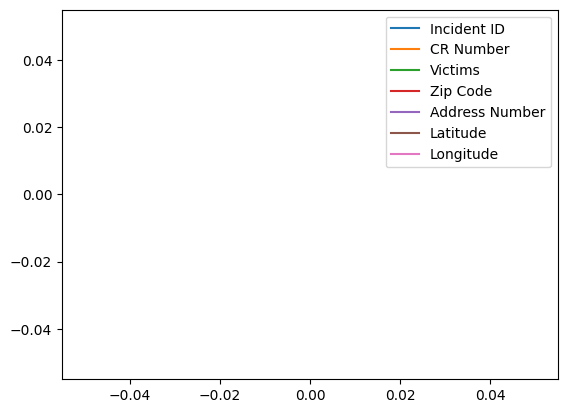

In [29]:
#df_remove_empty_cell = df.copy()
df_all = pd.read_csv("dataset_coursework1-1.csv", low_memory=False)
clean_df = df_all.dropna()
clean_df.plot()
#print(df.to_string())